# Human in the loop: active learning simulation (Milestone 4, Q2.4)

**Question this notebook answers:** *the operator can only check a few forecast windows per week. Which ones should
they check, and how much does that help the weekly retrain?*

**Why a human is needed at all.** The "true answer" for a forecast is the occupancy observed 4 hours later, so labels
arrive on their own. The problem is that **the telemetry itself can be wrong**: a frozen gateway that repeats its last
value, an ingestion bug that reports the lot as full, a gateway that reports 0 cars. These values look physically
possible, so the Milestone 3 `InputSanitizer` (clip to capacity, smooth single-step spikes) lets them through. If
nobody checks, the weekly retrain (Part 1: full retrain on a 6-month buffer) **learns from broken data**.

| Piece | Choice (from 2.1 – 2.3 and Part 1) |
|---|---|
| When a human steps in | a few forecasts per day, in a **daily digest**: the widest intervals (2.3) or the most surprising ones |
| What the human does | checks the 4-hour block (site status, charger logs) and confirms it or enters the real plug count |
| How the input is used | verified windows go into the replay buffer with a **2× sample weight** |
| Model update | every Sunday: full retrain from scratch on the last 6 months (DLinear + Ridge + stacking + Split-CQR) |

**How we simulate it.** At the start of the JPL test period (26 April 2021) two things happen at once: the Milestone 3
**Time-of-Use drift** (arrivals 2.5 h later) and **sensor faults** on about 10% of the new telemetry. We know the clean
values, so a simulated operator can "check" a window by looking them up. We then replay the test period **week by
week** and compare six ways of using (or not using) the operator.

## 1. Setup and settings

In [1]:
import contextlib
import io
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Ridge
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler

sys.path.insert(0, "src")
from models.train_neural import DLinear, fit, make_tensors, window_scale   # Milestone 2 model code

warnings.filterwarnings("ignore", category=ConvergenceWarning)

OUT = "outputs/hitl"
os.makedirs(OUT, exist_ok=True)
SITE, CAPACITY = "jpl", 56.0      # JPL has 56 ports
L, H = 672, 16                    # model window: 1 week of history, 4 hours ahead
DAY, WEEK = 96, 672               # in 15-minute steps

# Scenario
SHIFT_STEPS = 10                  # Time-of-Use drift from Milestone 3: arrivals 10 steps (2.5 h) later
FAULT_RATE = 0.10                 # share of the new telemetry hit by sensor faults

# Weekly update (Part 1 design)
BUFFER_DAYS = 182                 # sliding-window replay buffer: last 6 months
CALIB_DAYS = 14                   # most recent 2 weeks: early stopping, stacking and Split-CQR
VERIFIED_WEIGHT = 2.0             # sample weight of human-verified windows (section 2.3)
EPOCHS, PATIENCE, LR, BATCH = 30, 5, 1e-3, 256   # Milestone 2 hyperparameters

# Human in the loop
BUDGETS = [3, 7, 14]              # windows the operator checks per week (spread over the daily digests)
ERROR_RATE = 0.05                 # chance the operator misses a fault and confirms bad data
MINUTES_PER_QUERY = 3             # operator time per checked window
SEEDS = [0, 1, 2]                 # each seed = different faults, query draws and training noise
CYCLES = 8                        # weekly updates to replay

## 2. Rebuild the occupancy series

The data file stores training examples (1 week of history → the next 4 hours), one every 15 minutes, so the same
moment is copied in hundreds of examples. To break a sensor at a given moment in section 3, we first turn the
examples back into one simple table, *time → cars plugged in*, change it there once, and cut new examples from it
afterwards with `windows()`.

In [2]:
d = np.load(f"outputs/{SITE}_occupancy_data.npz")
timestamps = pd.to_datetime(d["timestamps"])
T = len(timestamps)
series = np.full(T, np.nan, dtype=np.float32)
calendar = np.full((T, d["train_X_cal"].shape[2]), np.nan, dtype=np.float32)
for split in ["train", "val", "test"]:
    o = d[f"{split}_origins"]
    target_steps = o[:, None] + np.arange(H)
    series[target_steps], calendar[target_steps] = d[f"{split}_y"], d[f"{split}_X_cal"]
    for first in np.r_[0, np.flatnonzero(np.diff(o) > 1) + 1]:    # start of each continuous run
        series[o[first] - L:o[first]] = d[f"{split}_X_hist"][first]

# The few history-only steps have no saved calendar row: rebuild it from the clock (same features as data_audit)
gap = np.isnan(calendar).any(axis=1)
hour = (timestamps.hour + timestamps.minute / 60).to_numpy()[gap]
dow = timestamps.dayofweek.to_numpy()[gap]
calendar[gap] = np.c_[np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24),
                      np.sin(2 * np.pi * dow / 7), np.cos(2 * np.pi * dow / 7), np.zeros(gap.sum())]

valid_origins = np.sort(np.r_[d["train_origins"], d["val_origins"], d["test_origins"]])
ONSET = int(d["test_origins"][0])                                     # drift and faults start here
breaks = np.flatnonzero(np.diff(d["test_origins"]) > 1)
STREAM_END = int(d["test_origins"][breaks[0]] + H)                    # stop at the July 2021 data outage


def windows(origins, values):
    # (history, calendar, target) arrays for a list of forecast origins, read from a 1-D series
    origins = np.asarray(origins)
    return (values[origins[:, None] + np.arange(-L, 0)], calendar[origins[:, None] + np.arange(H)],
            values[origins[:, None] + np.arange(H)])


def origins_between(start, end):
    # forecasts whose whole 4-hour target lies in [start, end)
    return valid_origins[(valid_origins >= start) & (valid_origins + H <= end)]

Sanity check: the rebuilt series must give back every saved window exactly.

In [3]:
for split in ["train", "val", "test"]:
    h, c, y = windows(d[f"{split}_origins"], series)
    diff = max(np.abs(h - d[f"{split}_X_hist"]).max(), np.abs(c - d[f"{split}_X_cal"]).max(),
               np.abs(y - d[f"{split}_y"]).max())
    print(f"{split:5s} {len(y):6,} windows | max difference {diff}")
print(f"\nNew regime starts {timestamps[ONSET]:%Y-%m-%d %H:%M} UTC; {(STREAM_END - ONSET) / WEEK:.1f} continuous weeks "
      f"before the July outage; we replay {CYCLES} weekly updates (+1 week to score the last one).")

train 57,242 windows | max difference 0.0
val   12,255 windows | max difference 0.0
test  12,270 windows | max difference 0.0

New regime starts 2021-04-26 03:00 UTC; 12.5 continuous weeks before the July outage; we replay 8 weekly updates (+1 week to score the last one).


## 3. The new regime: drift + sensor faults

* **Drift** (same as Milestone 3): from the onset, the whole occupancy curve arrives `SHIFT_STEPS` later relative to
  the clock. Calendar features stay on real clock time.
* **Faults**, injected into the drifted telemetry until about 10% of the steps are affected:

| Fault | What happens | Duration |
|---|---|---|
| `frozen` | gateway stops updating and repeats its last reading | 2 – 8 h |
| `stuck_high` | ingestion bug reports the lot as (nearly) full | 30 – 90 min |
| `dropout` | gateway reports 0 cars plugged in | 2 – 6 h |

Three versions of the series exist from now on: `clean` (the truth, only the simulated operator sees it), `received`
(what the pipeline gets) and, per policy, `curated` (received + whatever the operator has corrected).

In [4]:
def make_regime(seed):
    rng = np.random.default_rng(seed)
    clean = series.copy()
    clean[ONSET:] = series[ONSET - SHIFT_STEPS:T - SHIFT_STEPS]          # Time-of-Use drift
    received, kind = clean.copy(), np.full(T, "", dtype=object)
    while (kind[ONSET:STREAM_END] != "").mean() < FAULT_RATE:
        fault = rng.choice(["frozen", "stuck_high", "dropout"], p=[0.45, 0.20, 0.35])
        length = {"frozen": rng.integers(8, 33), "stuck_high": rng.integers(2, 7), "dropout": rng.integers(8, 25)}[fault]
        s = int(rng.integers(ONSET, STREAM_END - length))
        if (kind[s:s + length] != "").any():
            continue                                                     # no overlapping faults
        received[s:s + length] = {"frozen": clean[s - 1], "dropout": 0.0,
                                  "stuck_high": CAPACITY - rng.integers(0, 3, length)}[fault]
        kind[s:s + length] = fault
    return clean, received, kind


def sanitizer_changes(values):
    # Number of steps the two Milestone 3 InputSanitizer rules would change:
    # out of range [0, capacity], or a single-step spike (> 15 cars away from both neighbours)
    out_of_range = (values < 0) | (values > CAPACITY)
    jump = np.abs(np.diff(values)) > 15
    spike = np.r_[False, jump[:-1] & jump[1:], False]
    return int((out_of_range | spike).sum())


regimes = {seed: make_regime(seed) for seed in SEEDS}
fault_table = []
for seed, (clean, received, kind) in regimes.items():
    new = slice(ONSET, STREAM_END)
    changed = received[new] != clean[new]
    row = {"seed": seed}
    for fault in ["frozen", "stuck_high", "dropout"]:
        row[f"{fault} steps"] = int((kind[new] == fault).sum())
    row["fault steps (%)"] = 100 * (kind[new] != "").mean()
    row["steps that really differ (%)"] = 100 * changed.mean()
    row["steps fixed by M3 sanitizer"] = sanitizer_changes(received[new])
    fault_table.append(row)
pd.DataFrame(fault_table).set_index("seed").round(1)

,frozen steps,stuck_high steps,dropout steps,fault steps (%),steps that really differ (%),steps fixed by M3 sanitizer
seed,,,,,,
0,387,40,420,10.1,6.7,0
1,506,43,298,10.1,7.2,0
2,509,45,299,10.2,7.2,0


"Really differ" is lower than "fault steps" because some faults are invisible (a 0-dropout at night when the lot is
empty anyway, a frozen value during a quiet hour). **The Milestone 3 sanitizer changes none of the faulty steps**: they
are all inside the physical range and none is a single-step spike. This is the gap the operator fills.

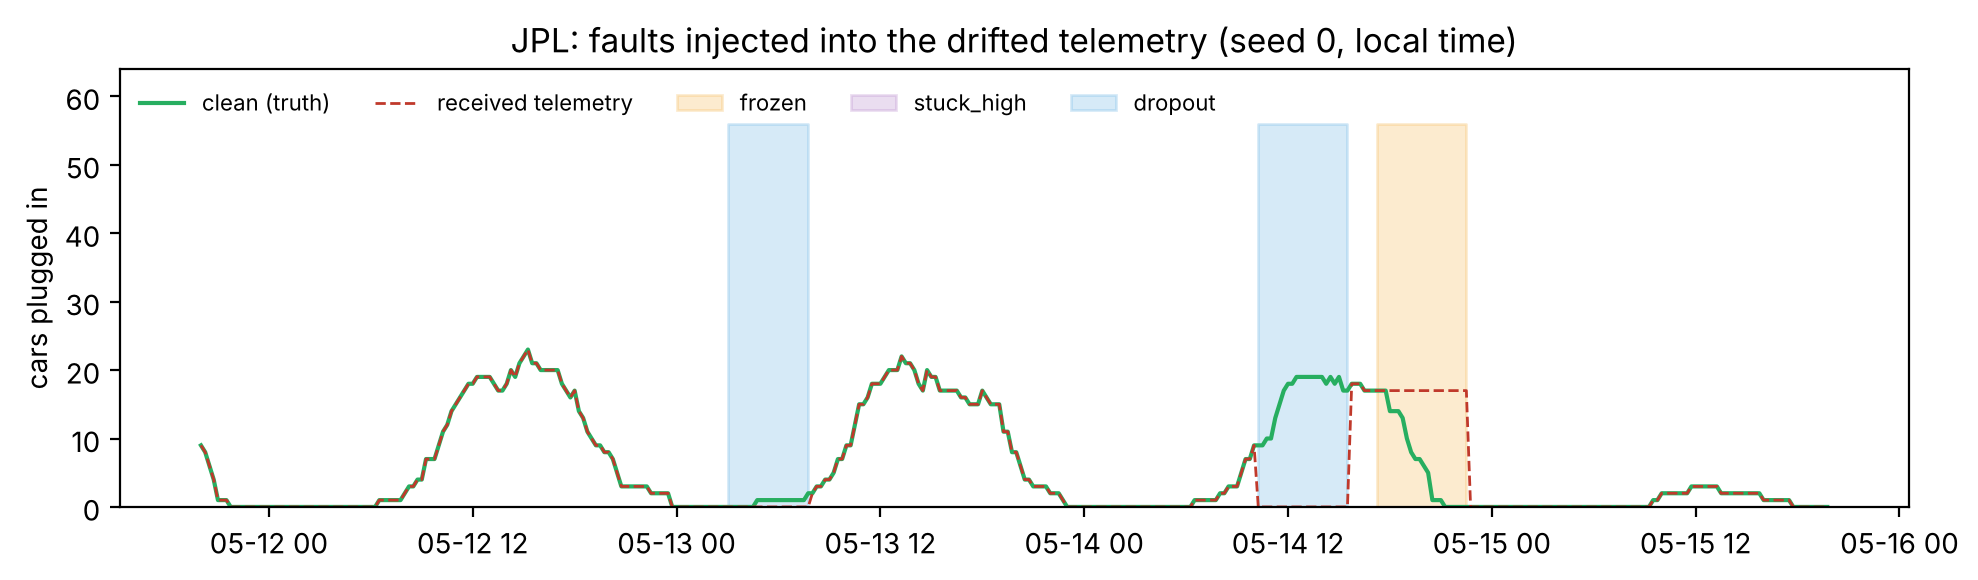

In [5]:
clean, received, kind = regimes[SEEDS[0]]
# show the 4-day stretch (first 3 weeks) with the most visible fault types
def visible_kinds(s):
    k = kind[s:s + 4 * DAY][received[s:s + 4 * DAY] != clean[s:s + 4 * DAY]]
    return len(set(k)), len(k)
start = max(range(ONSET, ONSET + 17 * DAY, DAY), key=visible_kinds)
span = slice(start, start + 4 * DAY)
t = timestamps[span].tz_convert("America/Los_Angeles")
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, clean[span], color="#27ae60", lw=1.5, label="clean (truth)")
ax.plot(t, received[span], color="#c0392b", lw=1, ls="--", label="received telemetry")
for fault, color in [("frozen", "#f5b041"), ("stuck_high", "#af7ac5"), ("dropout", "#5dade2")]:
    ax.fill_between(t, 0, CAPACITY, where=kind[span] == fault, color=color, alpha=0.25, step="mid", label=fault)
ax.set_ylabel("cars plugged in")
ax.set_title("JPL: faults injected into the drifted telemetry (seed 0, local time)")
ax.legend(ncol=5, fontsize=8, frameon=False, loc="upper left")
ax.set_ylim(0, CAPACITY + 8)
fig.tight_layout()
fig.savefig(f"{OUT}/fault_example.png", dpi=160)
plt.show()

## 4. The forecaster and the weekly update

Same stack as the Milestone 3 drift experiment, so numbers are comparable:

1. **DLinear** predicts the 10th, 50th and 90th percentile (pinball loss, early stopping), trained with weighted
   sampling so verified windows are drawn twice as often;
2. **Ridge** predicts the median (same weights);
3. a **stacking** Ridge per lead time combines the two medians;
4. the interval is the stacked median ± half the DLinear 10–90 width, clipped to [0, 56], then widened by **Split-CQR**
   on the last 14 days (80% target).

`train` is the Part 1 weekly update: take every window of the last 6 months, keep the last 14 days for calibration,
retrain everything **from scratch**.

In [6]:
def dlinear_forecast(net, hist, cal):
    net.eval()
    with torch.no_grad():
        h, c = make_tensors(hist, cal, None)
        return net(h, c).numpy() * window_scale(hist)[:, :, None]       # (n, 16, 3) in cars


def ridge_features(hist, cal):
    return np.concatenate([hist, cal.reshape(len(cal), -1)], axis=1)


def raw_interval(model, hist, cal):
    dl = dlinear_forecast(model["dlinear"], hist, cal)
    rd = model["ridge"].predict(model["scaler"].transform(ridge_features(hist, cal)))
    point = np.column_stack([m.predict(np.c_[dl[:, h, 1], rd[:, h]]) for h, m in enumerate(model["stack"])])
    half = 0.5 * (dl[..., 2] - dl[..., 0])
    return point, np.maximum(point - half, 0), np.minimum(point + half, CAPACITY), dl[..., 1], rd


def forecast(model, hist, cal):
    point, lower, upper, dl, rd = raw_interval(model, hist, cal)
    q = model["cqr"]
    return {"point": point, "lower": lower - q, "upper": upper + q, "dlinear": dl, "ridge": rd}


def train(values, verified, now, seed):
    # Weekly update: full retrain on the 6-month buffer that ends at `now`
    buffer = origins_between(now - BUFFER_DAYS * DAY, now)
    cut = now - CALIB_DAYS * DAY
    fit_o, calib_o = buffer[buffer + H <= cut], buffer[buffer >= cut]
    is_verified = verified[fit_o[:, None] + np.arange(H)].any(axis=1)
    w = np.where(is_verified, VERIFIED_WEIGHT, 1.0)
    (th, tc, ty), (ch, cc, cy) = windows(fit_o, values), windows(calib_o, values)

    torch.manual_seed(seed)
    sampler = WeightedRandomSampler(torch.as_tensor(w), len(w), generator=torch.Generator().manual_seed(seed))
    loader = DataLoader(TensorDataset(*make_tensors(th, tc, ty)), batch_size=BATCH, sampler=sampler)
    with contextlib.redirect_stdout(io.StringIO()):                     # fit() prints every epoch
        net, history = fit(DLinear(L, H, tc.shape[2]), loader, make_tensors(ch, cc, cy),
                           torch.device("cpu"), EPOCHS, PATIENCE, LR, "DLinear")

    scaler = StandardScaler().fit(ridge_features(th, tc))
    ridge = Ridge(alpha=10.0).fit(scaler.transform(ridge_features(th, tc)), ty, sample_weight=w / w.mean())
    model = {"dlinear": net, "scaler": scaler, "ridge": ridge, "stack": None, "cqr": 0.0}

    # Stacking and Split-CQR on the calibration weeks
    dl, rd = dlinear_forecast(net, ch, cc), ridge.predict(scaler.transform(ridge_features(ch, cc)))
    model["stack"] = [Ridge(alpha=10.0, positive=True).fit(np.c_[dl[:, h, 1], rd[:, h]], cy[:, h]) for h in range(H)]
    _, lower, upper, _, _ = raw_interval(model, ch, cc)
    scores = np.maximum(lower - cy, cy - upper)
    k = int(np.ceil((len(cy) + 1) * 0.8))
    model["cqr"] = np.partition(scores, k - 1, axis=0)[k - 1]           # one correction per lead time
    model["info"] = {"windows": len(fit_o), "verified windows": int(is_verified.sum()), "epochs": len(history)}
    return model


def score(model, origins, values):
    h, c, y = windows(origins, values)
    f = forecast(model, h, c)
    err = y - f["point"]
    return {"mae": np.abs(err).mean(), "rmse": np.sqrt((err ** 2).mean()),
            "coverage": ((y >= f["lower"]) & (y <= f["upper"])).mean(), "width": (f["upper"] - f["lower"]).mean()}

### The starting model

Trained on the 6 months before the onset (validated data, no faults). It is the deployed model at week 0 for every
policy. Its error on the last clean pre-drift week vs the first drifted week shows what the drift does on its own.

In [7]:
clean, received, kind = regimes[SEEDS[0]]
t0 = time.perf_counter()
start_model = train(clean, np.zeros(T, bool), ONSET, seed=0)
print(f"trained in {time.perf_counter() - t0:.1f} s on {start_model['info']['windows']:,} windows "
      f"({start_model['info']['epochs']} epochs)")

no_drift = clean.copy()
no_drift[ONSET:] = series[ONSET:]                                        # same week, without the drift
week1 = origins_between(ONSET, ONSET + WEEK)
pd.DataFrame({"last week before onset": score(start_model, origins_between(ONSET - WEEK, ONSET), clean),
              "week 1, no drift": score(start_model, week1, no_drift),
              "week 1, with drift": score(start_model, week1, clean)}).round(3)

trained in 8.8 s on 13,147 windows (19 epochs)


,last week before onset,"week 1, no drift","week 1, with drift"
mae,1.368,1.325,2.054
rmse,2.089,2.073,3.234
coverage,0.829,0.839,0.768
width,4.611,4.658,5.597


## 5. Which windows should the operator check?

Every evening the system has, for each forecast whose 4 hours ended that day, the 80% interval it published in the
morning **and** the telemetry that came in since (the real value is known 4 hours later). Three strategies are compared:

| Strategy | Each evening, check… | Score |
|---|---|---|
| `uncertainty` | the forecasts with the **widest interval** (section 2.3: the model is least sure) | `width` = mean(upper − lower) |
| `surprise` | the forecasts where the telemetry fell **furthest outside** the interval (the model did not expect it) | `surprise` = mean of max(lower − y, y − upper, 0) |
| `random` | random forecasts (baseline: a strategy is only useful if it beats chance) | – |

Example: the model said 10 – 25 cars and the sensor reported 0 → `surprise` = 10 cars. `surprise` is the same quantity
Split-CQR uses to calibrate the intervals, so it needs nothing new.

**No overlap rule** (`surprise` only): a sensor fault usually lasts hours, so the most surprising forecasts of a day are
often neighbours (13:00 and 13:15) covering the same broken hours. When more than one check is allowed per evening, a
forecast whose 4 hours overlap one already picked is skipped. With one check per evening the rule has no effect.

First, how well does each score point at windows that really contain a fault? We measure it with the AUC on the first
two drifted weeks, using the starting model: take one faulty and one healthy window at random, how often does the
faulty one get the higher score? 0.5 = no better than chance, 1.0 = perfect.

In [8]:
def window_scores(model, origins, values):
    h, c, y = windows(origins, values)          # y = telemetry received for the 4 hours (known by the evening)
    f = forecast(model, h, c)
    return pd.DataFrame({
        "width": (f["upper"] - f["lower"]).mean(axis=1),                                    # 2.3: how unsure
        "surprise": np.maximum(np.maximum(f["lower"] - y, y - f["upper"]), 0).mean(axis=1),  # how unexpected
    })


auc = {}
for seed, (clean, received, kind) in regimes.items():
    o = origins_between(ONSET, ONSET + 2 * WEEK)
    bad = (received != clean)[o[:, None] + np.arange(H)].any(axis=1)     # target block has a real fault
    s = window_scores(start_model, o, received)
    auc[seed] = {name: roc_auc_score(bad, s[name]) for name in s}
auc = pd.DataFrame(auc).T
auc.loc["mean"] = auc.mean()
auc.round(3)

,width,surprise
0,0.888,0.949
1,0.465,0.850
2,0.511,0.680
mean,0.621,0.826


**Finding:** `surprise` points at faulty windows much better than `width`: AUC **0.83** on average (0.68 – 0.95
depending on the faults) against **0.62** (0.47 – 0.89). A wide interval means the model is unsure, which is not the
same as the telemetry being wrong: a frozen value or a false 0 can sit inside a narrow interval, but it usually ends up
outside the range the model expected. Width also gives neighbouring windows (15 minutes apart) almost the same score,
so the widest intervals of a day often cover the same hours.

In [9]:
def pick(strategy, origins, scores, k, verified, rng):
    open_ = ~verified[origins[:, None] + np.arange(H)].all(axis=1)        # never re-check a verified block
    candidates = np.flatnonzero(open_)
    if k == 0 or len(candidates) == 0:
        return []
    if strategy == "random":
        return list(rng.choice(candidates, size=min(k, len(candidates)), replace=False))
    if strategy == "uncertainty":                                         # 2.3: the k widest intervals
        return list(candidates[np.argsort(-scores["width"].to_numpy()[candidates], kind="stable")][:k])
    chosen = []                                                           # surprise: most unexpected first,
    for i in candidates[np.argsort(-scores["surprise"].to_numpy()[candidates], kind="stable")]:
        if all(abs(origins[i] - origins[j]) >= H for j in chosen):        # skipping overlapping 4-hour blocks
            chosen.append(i)
            if len(chosen) == k:
                break
    return chosen


def per_day(budget, day):
    # spread a weekly budget evenly over the 7 daily digests (7/week -> 1 per day)
    return (day + 1) * budget // 7 - day * budget // 7

## 6. The simulated operator

For a checked window the operator looks at its 4-hour block. If the telemetry is wrong they enter the real plug
counts (we copy them from `clean`), except with probability `ERROR_RATE` where they miss it. If the telemetry is
right they confirm it. Either way the block is marked **verified** (2× weight in the next retrain).

In [10]:
def operator_check(origin, clean, curated, verified, rng):
    block = slice(origin, origin + H)
    wrong = bool((curated[block] != clean[block]).any())
    missed = wrong and rng.random() < ERROR_RATE
    if not missed:
        curated[block] = clean[block]
    verified[block] = True
    return "missed" if missed else "corrected" if wrong else "confirmed"

## 7. The weekly replay

For each policy, week by week:
1. **Score** the deployed model on this week's clean data (MAE, RMSE, 80% coverage, width). Cycle 0 = before any
   update.
2. **Daily digests** (active learning policies only): each evening, score the windows that finished that day, pick
   `per_day(budget, day)` of them, the operator checks them.
3. **Sunday update**: retrain on the 6-month buffer built from `curated`, verified windows weighted 2×.

| Policy | Human | Update |
|---|---|---|
| `stale` | none | never retrained (the model from section 4) |
| `no_human` | none | weekly retrain on the received telemetry, faults included |
| `random`, `uncertainty`, `surprise` | `budget` windows per week | weekly retrain |
| `all_verified` | every new window (upper bound: 100% labelling) | weekly retrain |

In [11]:
def replay(policy, budget, seed):
    clean, received, kind = regimes[seed]
    curated, verified = received.copy(), np.zeros(T, bool)
    if policy == "all_verified":
        curated[ONSET:STREAM_END], verified[ONSET:STREAM_END] = clean[ONSET:STREAM_END], True
    rng = np.random.default_rng(seed + 99)
    model, queries, rows = start_models[seed], [], []

    for cycle in range(CYCLES + 1):
        week = ONSET + cycle * WEEK
        row = {"policy": policy, "budget": budget, "seed": seed, "cycle": cycle}
        t = time.perf_counter()
        row.update(score(model, origins_between(week, week + WEEK), clean))   # 1. this week's clean truth
        row["inference_ms_per_window"] = (time.perf_counter() - t) * 1000 / len(origins_between(week, week + WEEK))

        seen = slice(ONSET, week)                                             # telemetry received so far
        real_fault = (kind[seen] != "") & (received[seen] != clean[seen])
        row["faults repaired (%)"] = 100 * (curated[seen] == clean[seen])[real_fault].mean() if real_fault.any() else np.nan
        row["labels"] = len(queries) if policy != "all_verified" else len(origins_between(ONSET, week))
        row["verified steps (%)"] = 100 * verified[seen].mean() if cycle else 0.0
        if cycle == CYCLES:
            rows.append(row)
            break

        digest_ms = []
        if policy in ("random", "uncertainty", "surprise"):                    # 2. daily digests
            for day in range(7):
                today = origins_between(week + day * DAY, week + (day + 1) * DAY)
                t = time.perf_counter()
                s = window_scores(model, today, curated)
                chosen = pick(policy, today, s, per_day(budget, day), verified, rng)
                digest_ms.append((time.perf_counter() - t) * 1000)
                for i in chosen:
                    verdict = operator_check(int(today[i]), clean, curated, verified, rng)
                    queries.append({"policy": policy, "budget": budget, "seed": seed, "cycle": cycle, "day": day,
                                    "window start": timestamps[today[i]], "fault": kind[today[i]:today[i] + H].max(),
                                    "verdict": verdict, **s.iloc[i].round(3).to_dict()})
        row["digest_ms"] = np.mean(digest_ms) if digest_ms else np.nan

        if policy != "stale":                                                 # 3. Sunday update
            t = time.perf_counter()
            model = train(curated, verified, week + WEEK, seed=seed * 100 + cycle + 1)
            row["update_s"] = time.perf_counter() - t
            row["verified windows in buffer"] = model["info"]["verified windows"]
        rows.append(row)
    return rows, queries

## 8. Run every policy

One starting model per seed, then every policy and budget. This is the long cell (about 25 minutes on a 2-core CPU).

In [12]:
POLICIES = [("stale", 0), ("no_human", 0)] + [(p, b) for b in BUDGETS for p in ["random", "uncertainty", "surprise"]] \
           + [("all_verified", 0)]
start_models, results, query_log = {}, [], []
t_all = time.perf_counter()
for seed in SEEDS:
    start_models[seed] = train(regimes[seed][0], np.zeros(T, bool), ONSET, seed=seed)
    for policy, budget in POLICIES:
        rows, queries = replay(policy, budget, seed)
        results += rows
        query_log += queries
    print(f"seed {seed} done ({(time.perf_counter() - t_all) / 60:.1f} min)")

results = pd.DataFrame(results)
query_log = pd.DataFrame(query_log)
results.to_csv(f"{OUT}/hitl_cycles_{SITE}.csv", index=False)
query_log.to_csv(f"{OUT}/hitl_queries_{SITE}.csv", index=False)

seed 0 done (12.8 min)


seed 1 done (23.8 min)


seed 2 done (34.8 min)


## 9. Results

Every setup is judged on weeks 1 – 8 (after the updates), averaged over the 3 seeds:

* **MAE**: average forecast error in cars (lower is better).
* **damage removed**: where the setup lands between `no_human` (0%: retrains on the faulty data) and `all_verified`
  (100%: retrains on perfect data).
* **faults fixed**: share of the broken telemetry repaired before retraining.
* **operator h/week**: time spent by the operator, at 3 minutes per check.

This part reads the files saved in section 8, so it can be re-run on its own.

In [ ]:
results = pd.read_csv(f"{OUT}/hitl_cycles_{SITE}.csv")
query_log = pd.read_csv(f"{OUT}/hitl_queries_{SITE}.csv")
updated = results[results["cycle"] >= 1]                                   # weeks after the first update
last = results[results["cycle"] == CYCLES]


def name(policy, budget):
    return f"{policy}, {budget}/week" if budget else policy


per_seed = updated.groupby(["policy", "budget", "seed"])["mae"].mean()     # one MAE per setup and seed
by_setup = lambda col, df: df.groupby(["policy", "budget"])[col].mean()
table = pd.DataFrame({"MAE": per_seed.groupby(["policy", "budget"]).mean()})
worst, best = table.loc[("no_human", 0), "MAE"], table.loc[("all_verified", 0), "MAE"]
table["damage removed (%)"] = 100 * (worst - table["MAE"]) / (worst - best)
table.loc[("stale", 0), "damage removed (%)"] = np.nan                     # never retrains: not on this scale
table["faults fixed (%)"] = by_setup("faults repaired (%)", last)
table["checks that found a fault (%)"] = query_log.groupby(["policy", "budget"])["verdict"].apply(
    lambda v: 100 * (v != "confirmed").mean())
table["operator h/week"] = by_setup("labels", last) / CYCLES * MINUTES_PER_QUERY / 60

ORDER = [("no_human", 0), ("stale", 0)] + [(p, b) for b in BUDGETS for p in ["random", "uncertainty", "surprise"]] \
        + [("all_verified", 0)]
table = table.reindex(ORDER)
table.index = [name(p, b) for p, b in table.index]
table.to_csv(f"{OUT}/hitl_summary_{SITE}.csv")
table.round(2).fillna("–")

,MAE,damage removed (%),faults fixed (%),checks that found a fault (%),operator h/week
no_human,1.86,0.0,0.00,–,0.00
stale,1.52,–,0.00,–,0.00
"random, 3/week",1.81,13.61,7.17,19.44,0.15
"uncertainty, 3/week",1.83,9.14,7.43,19.44,0.15
"surprise, 3/week",1.85,4.12,7.06,9.72,0.15
"random, 7/week",1.78,22.1,14.17,13.69,0.35
"uncertainty, 7/week",1.83,10.16,13.20,14.88,0.35
"surprise, 7/week",1.80,17.8,20.60,17.26,0.35
"random, 14/week",1.75,32.01,31.34,13.69,0.70
"uncertainty, 14/week",1.77,26.8,17.72,14.29,0.70


**Key results**

* **Without a human, the weekly retrain hurts:** MAE 1.86 against 1.50 when everything is checked (+24%), and worse
  than never retraining (`stale`, 1.52). The faults get into the training data.
* **At one check per evening or less (3 – 7 per week), no strategy beats `random`.** The differences are smaller than
  the variation between seeds.
* **At two checks per evening (14 per week), `surprise` removes 62% of the damage**, against 32% for `random` and 27%
  for `uncertainty`, for 0.7 operator-hours per week (checking everything would take 33.5).
* **`uncertainty` (2.3) fixes only 18% of the faults** at 14 per week (49% for `surprise`): a wide interval does not
  mean the data is wrong, and the widest intervals of a day often cover the same hours.

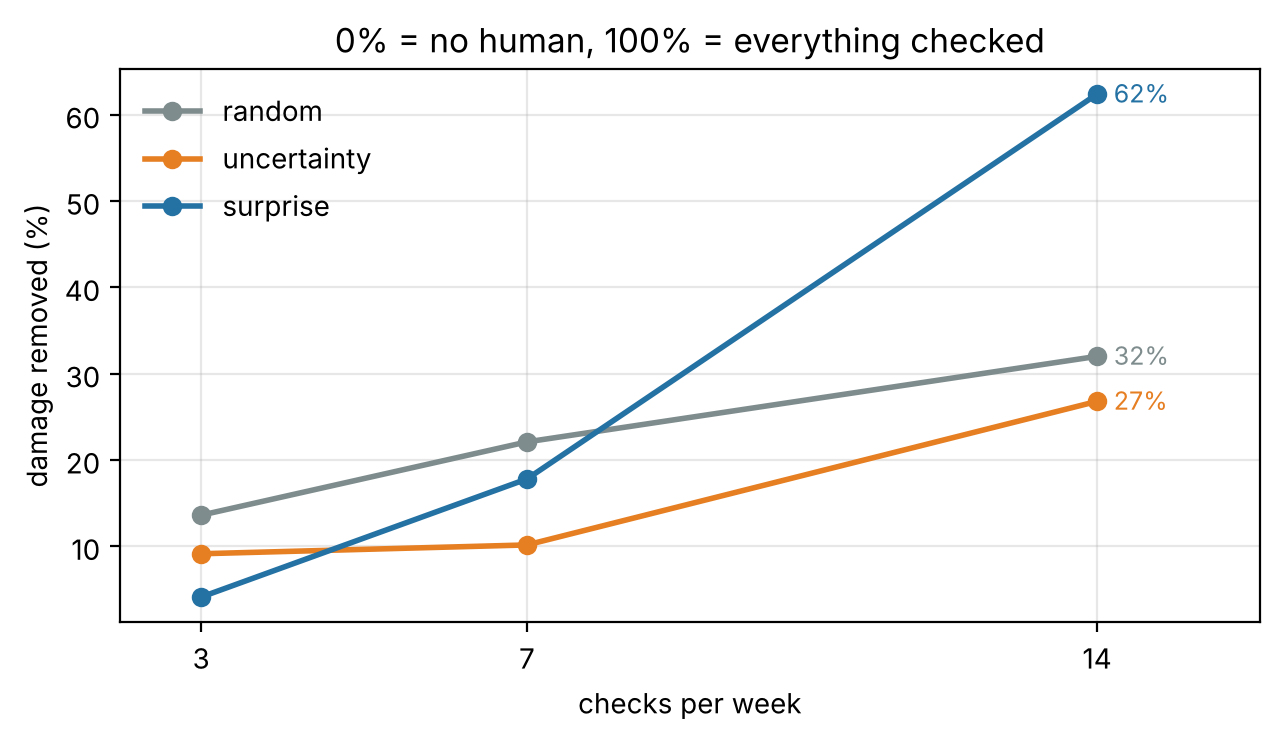

In [ ]:
COLORS = {"no_human": "#c0392b", "stale": "#8c8c8c", "random": "#7f8c8d", "uncertainty": "#e67e22",
          "surprise": "#2471a3", "all_verified": "#27ae60"}

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for policy in ["random", "uncertainty", "surprise"]:
    y = [table.loc[name(policy, b), "damage removed (%)"] for b in BUDGETS]
    ax.plot(BUDGETS, y, marker="o", lw=2, color=COLORS[policy], label=policy)
    ax.annotate(f"{y[-1]:.0f}%", (BUDGETS[-1], y[-1]), xytext=(6, -3), textcoords="offset points",
                color=COLORS[policy], fontsize=9)
ax.set_xticks(BUDGETS)
ax.set_xlabel("checks per week")
ax.set_ylabel("damage removed (%)")
ax.set_title("0% = no human, 100% = everything checked")
ax.set_xlim(2, 16)
ax.grid(alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(f"{OUT}/damage_removed_{SITE}.png", dpi=160)
plt.show()

### Week by week, at 14 checks per week

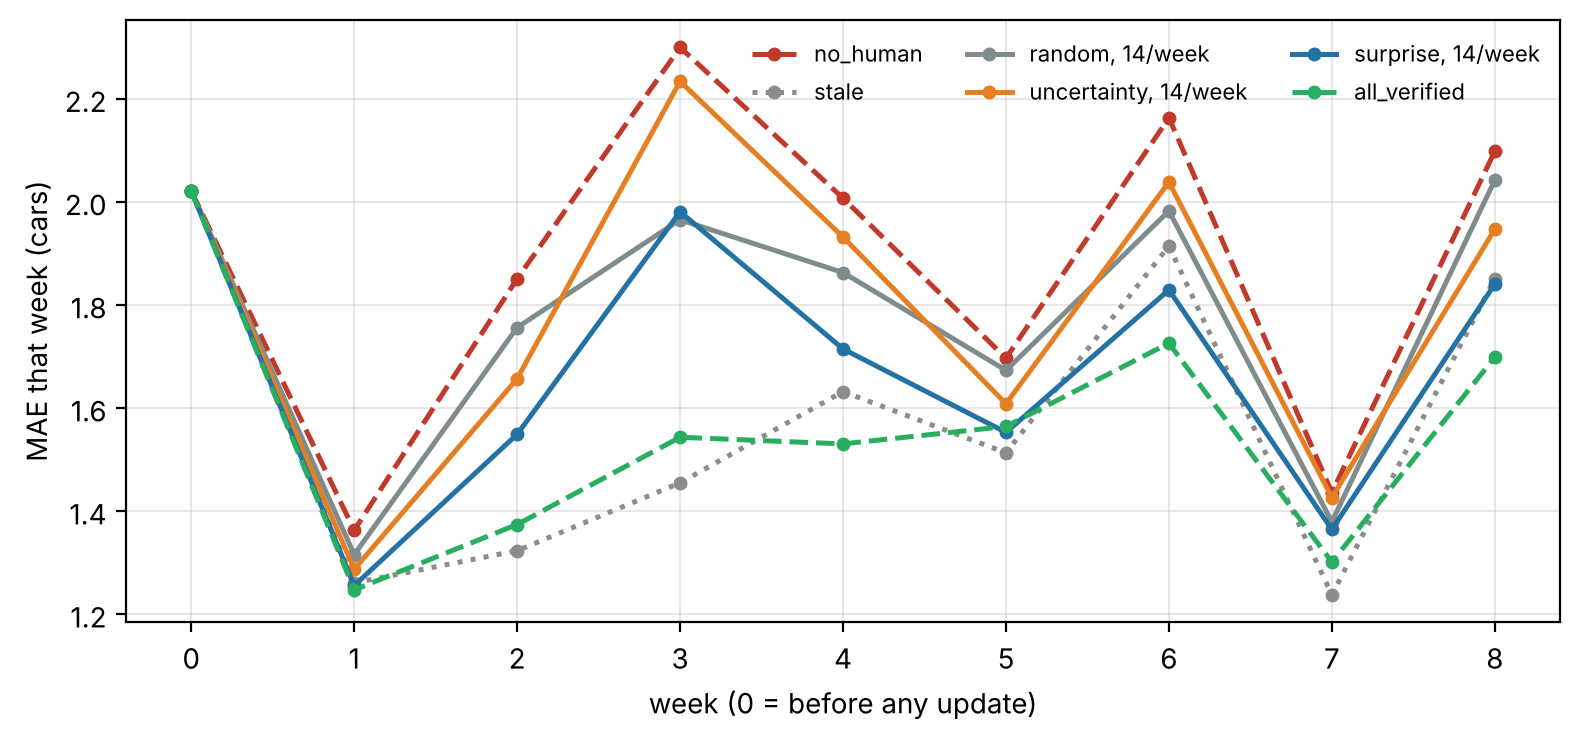

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for policy, budget, ls in [("no_human", 0, "--"), ("stale", 0, ":"), ("random", 14, "-"), ("uncertainty", 14, "-"),
                           ("surprise", 14, "-"), ("all_verified", 0, "--")]:
    g = results[(results["policy"] == policy) & (results["budget"] == budget)].groupby("cycle")["mae"].mean()
    ax.plot(g.index, g, ls, color=COLORS[policy], marker="o", ms=4, lw=1.8, label=name(policy, budget))
ax.set_xticks(range(CYCLES + 1))
ax.set_xlabel("week (0 = before any update)")
ax.set_ylabel("MAE that week (cars)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=3, frameon=False)
fig.tight_layout()
fig.savefig(f"{OUT}/mae_per_week_{SITE}.png", dpi=160)
plt.show()

Some weeks are harder for everyone (weeks 3, 6 and 8), so compare the lines within a week. The red line (`no_human`) is above the dotted gray line (`stale`) every week: retraining on faulty data is worse than not retraining. `surprise` (blue) is the best of the three strategies in 7 of the 8 weeks and stays closest to `all_verified` (green): on average 0.14 cars above it, against 0.37 for `no_human`.

In [ ]:
# Is it luck? The 14-per-week setups, one MAE per seed (lower is better)
w14 = updated[updated["budget"] == 14].pivot_table(index=["seed", "cycle"], columns="policy", values="mae")
print(f"surprise beats random in {(w14['surprise'] < w14['random']).sum()} of {len(w14)} weeks (3 seeds x 8 weeks)")
per_seed.unstack("seed").loc[[("random", 14), ("uncertainty", 14), ("surprise", 14)]].round(2)

surprise beats random in 19 of 24 weeks (3 seeds x 8 weeks)


,seed,0,1,2
policy,budget,,,
random,14,1.64,1.89,1.71
uncertainty,14,1.63,1.92,1.75
surprise,14,1.53,1.77,1.61


`surprise` is better than `random` with all 3 seeds, so the result does not depend on where the faults happened to land.

## 10. Cost and stability

* **digest**: choosing the evening's checks; **retrain**: one Sunday update; **forecast**: one forecast (in batch).
* **spread across seeds**: how much the weekly MAE varies between seeds (lower = more predictable updates).

In [ ]:
cost = results[results["cycle"] < CYCLES].groupby(["policy", "budget"]).agg(
    digest_ms=("digest_ms", "mean"), retrain_s=("update_s", "mean"), forecast_ms=("inference_ms_per_window", "mean"))
cost["spread across seeds"] = updated.groupby(["policy", "budget", "cycle"])["mae"].std().groupby(["policy", "budget"]).mean()
cost = cost.reindex([("no_human", 0), ("random", 14), ("uncertainty", 14), ("surprise", 14), ("all_verified", 0)])
cost.index = [name(p, b) for p, b in cost.index]
cost.round(3).fillna("–")

,digest_ms,retrain_s,forecast_ms,spread across seeds
no_human,–,7.901,0.018,0.326
"random, 14/week",3.907,7.565,0.018,0.200
"uncertainty, 14/week",4.223,7.459,0.020,0.231
"surprise, 14/week",4.249,7.622,0.018,0.143
all_verified,–,7.241,0.019,0.012


The human loop costs almost nothing to run: a few milliseconds per evening to pick the checks, and the Sunday retrain
and the forecasts are unchanged. Repairing more faults also makes the updates more predictable.

## 11. Summary

* **The risk:** sensor faults get past the Milestone 3 sanitizer, and retraining on them makes the model 24% worse.
* **The human helps, with enough checks:** at least 2 per evening; below that, no strategy beats random.
* **What to check:** the forecasts that **surprised** the model (telemetry far outside the interval), not the most
  **uncertain** ones (widest interval, section 2.3). At 14 checks per week: 62% of the damage removed against 27%, for
  0.7 h/week.
* **Limits:** one site (JPL), simulated faults and operator, 3 seeds. Our faults land far from the expected range,
  which suits `surprise`; a small constant bias would be harder to catch.

**Files in `outputs/hitl/`:** `hitl_cycles_jpl.csv` (every setup, seed and week), `hitl_queries_jpl.csv` (every
check), `hitl_summary_jpl.csv` (the table above), `fault_example.png`, `damage_removed_jpl.png`,
`mae_per_week_jpl.png`.